# Financial inclusion in Pakistan: the analysis, step by step

This notebook walks through the analysis behind the dashboard and the memo. It does not just display results: each
step **recomputes** a result from the district table and **checks it against the pipeline's output**, so a reader can
see where the numbers come from.

Run the whole project first (`python -m fininc all`), then run the notebook from top to bottom.

1. The data
2. The national picture
3. Pakistan against other economies
4. Who is left out
5. Where the branches are
6. How many branches should a district have?
7. Types of district
8. Inequality and catch-up
9. A placement planner
10. The digital layer
11. Conclusions

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fininc").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import Image, display

from fininc import config, models
from fininc.paths import FIGURES
from fininc.results import load

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

r = load()
units = r.units
print(f"{len(units)} districts, {units['pop'].sum() / 1e6:.1f} million people, {units['branches_2024'].sum():,} branches")

120 districts, 241.5 million people, 18,322 branches


## 1. The data

Four public sources are joined at the level of the **district on its 2020 boundaries** (120 units). Branch and census data
describe districts; the Findex survey describes the country and groups of people. Population is checked against the
official provincial totals, which must match exactly.

In [2]:
check = pd.DataFrame(r.summary["quality"]["census_official_check"])
check[["province", "districts", "pop_2023", "official_2023", "diff_2023", "diff_2017"]]

,province,districts,pop_2023,official_2023,diff_2023,diff_2017
0,Punjab,36,127688922,127688922,0,0
1,Sindh,30,55696147,55696147,0,0
2,Khyber Pakhtunkhwa,35,40856097,40856097,0,0
3,Balochistan,34,14894402,14894402,0,0
4,Islamabad,1,2363863,2363863,0,0


In [3]:
assert (check[["diff_2023", "diff_2017"]] == 0).all().all()
units[["unit", "province", "pop", "urban_share", "literacy_female", "ses_index", "banks_2024", "mfb_2024",
       "branches_per_100k"]].sort_values("pop", ascending=False).head(8).round(1)

,unit,province,pop,urban_share,literacy_female,ses_index,banks_2024,mfb_2024,branches_per_100k
41,Karachi,Sindh,20382881.0,92.6,72.8,1.8,2628,77,13.3
58,Lahore,Punjab,13004135.0,100.0,77.6,1.9,1903,57,15.1
21,Faisalabad,Punjab,9075819.0,48.4,69.1,1.4,658,38,7.7
94,Rawalpindi,Punjab,6118911.0,68.8,78.4,1.8,813,39,13.9
23,Gujranwala,Punjab,5959750.0,60.3,75.4,1.7,450,32,8.1
92,Rahim Yar Khan,Punjab,5564703.0,24.1,40.1,0.4,282,37,5.7
75,Multan,Punjab,5362305.0,46.6,55.3,1.0,465,34,9.3
77,Muzaffargarh,Punjab,5015325.0,18.9,39.7,0.3,161,36,3.9


## 2. The national picture

Branches per 100,000 people, recomputed from the district table. The province table in the pipeline must agree.

In [4]:
by_province = units.groupby("province").agg(pop=("pop", "sum"), branches=("branches_2024", "sum"),
                                              rural_pop=("pop_rural", "sum"), rural_branches=("rural_branches_2024", "sum"))
by_province["per_100k"] = by_province["branches"] / by_province["pop"] * 1e5
by_province["rural_per_100k_rural"] = by_province["rural_branches"] / by_province["rural_pop"] * 1e5
assert np.allclose(by_province["per_100k"].sort_index(), r.provinces.set_index("province")["branches_per_100k"].sort_index())

total = units[["pop", "pop_rural", "branches_2024", "rural_branches_2024", "pop_urban", "urban_branches_2024"]].sum()
print(f"Rural: {total.pop_rural / total['pop']:.0%} of people, {total.rural_branches_2024 / total.branches_2024:.0%} of branches")
print(f"Per 100,000 rural people: {total.rural_branches_2024 / total.pop_rural * 1e5:.1f}; "
      f"per 100,000 urban people: {total.urban_branches_2024 / total.pop_urban * 1e5:.1f}")
by_province.sort_values("per_100k", ascending=False).round(1)

Rural: 61% of people, 30% of branches
Per 100,000 rural people: 3.7; per 100,000 urban people: 13.7


,pop,branches,rural_pop,rural_branches,per_100k,rural_per_100k_rural
province,,,,,,
Islamabad,2363863.0,732,1254991.0,38,31.0,3.0
Punjab,127688922.0,10318,75712955.0,3427,8.1,4.5
Sindh,55696147.0,4416,25639408.0,822,7.9,3.2
Khyber Pakhtunkhwa,40856097.0,2148,34724801.0,907,5.3,2.6
Balochistan,14894402.0,708,10282574.0,282,4.8,2.7


## 3. Pakistan against other economies

Account ownership against income, for every economy with both. A straight line on the log of income gives the
account ownership that income would predict; the gap is Pakistan's shortfall.

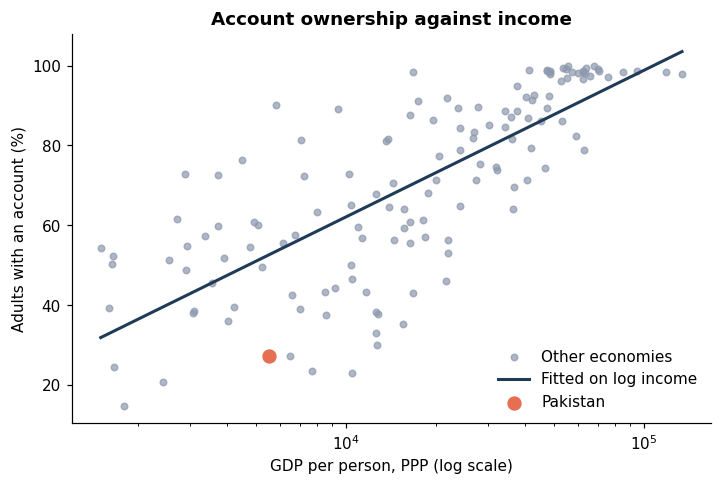

Pakistan 27.3% against 52.6% expected: a shortfall of 25.3 points
Rank from the lowest: 6 of 138


In [5]:
cc = r.cross
X = sm.add_constant(cc["gdp_pc_ppp"].map(np.log))
fit = sm.OLS(cc["account"], X).fit()
pak = cc[cc["country"] == "PAK"].iloc[0]
expected = fit.params.iloc[0] + fit.params.iloc[1] * np.log(pak["gdp_pc_ppp"])
assert abs(expected - pak["expected_account"]) < 0.01          # the pipeline's number

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(cc["gdp_pc_ppp"], cc["account"], s=18, color=config.GREY, alpha=0.7, label="Other economies")
grid = np.linspace(cc["gdp_pc_ppp"].min(), cc["gdp_pc_ppp"].max(), 200)
ax.plot(grid, fit.params.iloc[0] + fit.params.iloc[1] * np.log(grid), color=config.NAVY, lw=2, label="Fitted on log income")
ax.scatter(pak["gdp_pc_ppp"], pak["account"], s=70, color=config.ORANGE, zorder=3, label="Pakistan")
ax.set_xscale("log")
ax.set_xlabel("GDP per person, PPP (log scale)")
ax.set_ylabel("Adults with an account (%)")
ax.set_title("Account ownership against income")
ax.legend(frameon=False)
plt.show()
print(f"Pakistan {pak['account']:.1f}% against {expected:.1f}% expected: a shortfall of {expected - pak['account']:.1f} points")
print(f"Rank from the lowest: {int((cc['account'] <= pak['account']).sum())} of {len(cc)}")

## 4. Who is left out

Account ownership by group in the last two survey rounds, and the reasons adults give for having no bank account. The
reason labels are the World Bank's own wording.

In [6]:
seg = r.segments[r.segments["year"].isin([2021, 2024])].pivot_table(index="segment", columns="year", values="value")
seg["change"] = seg[2024] - seg[2021]
seg.sort_values("change").round(1)

year,2021,2024,change
segment,,,
Poorest 40%,17.6,13.6,-4.0
Out of the labour force,15.7,13.9,-1.7
Women,13.5,11.9,-1.6
Primary education or less,15.3,18.9,3.6
Older adults (25+),22.5,28.5,6.1
Young adults (15-24),18.1,24.3,6.2
All adults,21.0,27.3,6.3
Secondary education or more,35.3,46.7,11.4
Richest 60%,23.2,36.4,13.2


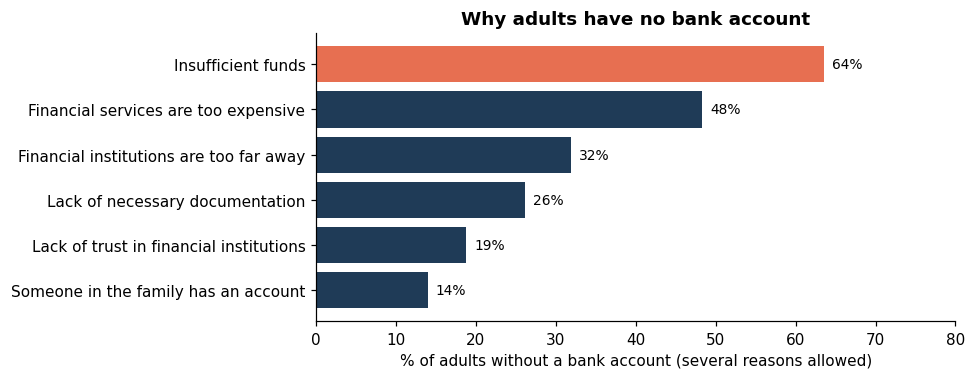

In [7]:
b = r.barriers.sort_values("share_of_unbanked")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(b["reason"], b["share_of_unbanked"], color=[config.ORANGE if v == b["share_of_unbanked"].max() else config.NAVY
                                                    for v in b["share_of_unbanked"]])
for y, v in enumerate(b["share_of_unbanked"]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 80)
ax.set_xlabel("% of adults without a bank account (several reasons allowed)")
ax.set_title("Why adults have no bank account")
plt.show()

## 5. Where the branches are

Branches per 100,000 people vary almost fifty-fold between districts. The districts below half the national average are the
"low-density" districts used throughout.

In [8]:
national = units["branches_2024"].sum() / units["pop"].sum() * 1e5
low = units["branches_per_100k"] < config.LOW_DENSITY_SHARE_OF_AVERAGE * national
print(f"National: {national:.2f} per 100,000. Districts below half of it: {low.sum()} holding "
      f"{units.loc[low, 'pop'].sum() / units['pop'].sum():.1%} of people")
assert low.sum() == r.headline["units_below_half_average"]

best = units.nlargest(5, "branches_per_100k")[["unit", "province", "pop", "branches_2024", "branches_per_100k"]]
worst = units.nsmallest(5, "branches_per_100k")[["unit", "province", "pop", "branches_2024", "branches_per_100k"]]
pd.concat([best, worst]).round(1)

National: 7.59 per 100,000. Districts below half of it: 41 holding 13.6% of people


,unit,province,pop,branches_2024,branches_per_100k
31,Islamabad,Islamabad,2363863.0,732,31.0
25,Gwadar,Balochistan,305160.0,54,17.7
37,Jhelum,Punjab,1382308.0,209,15.1
58,Lahore,Punjab,13004135.0,1960,15.1
24,Gujrat,Punjab,3219375.0,457,14.2
76,Musakhel,Balochistan,182275.0,0,0.0
35,Jhal Magsi,Balochistan,203368.0,1,0.5
113,Torghar,Khyber Pakhtunkhwa,200445.0,1,0.5
117,Washuk,Balochistan,302623.0,2,0.7
104,South Waziristan,Khyber Pakhtunkhwa,888675.0,6,0.7


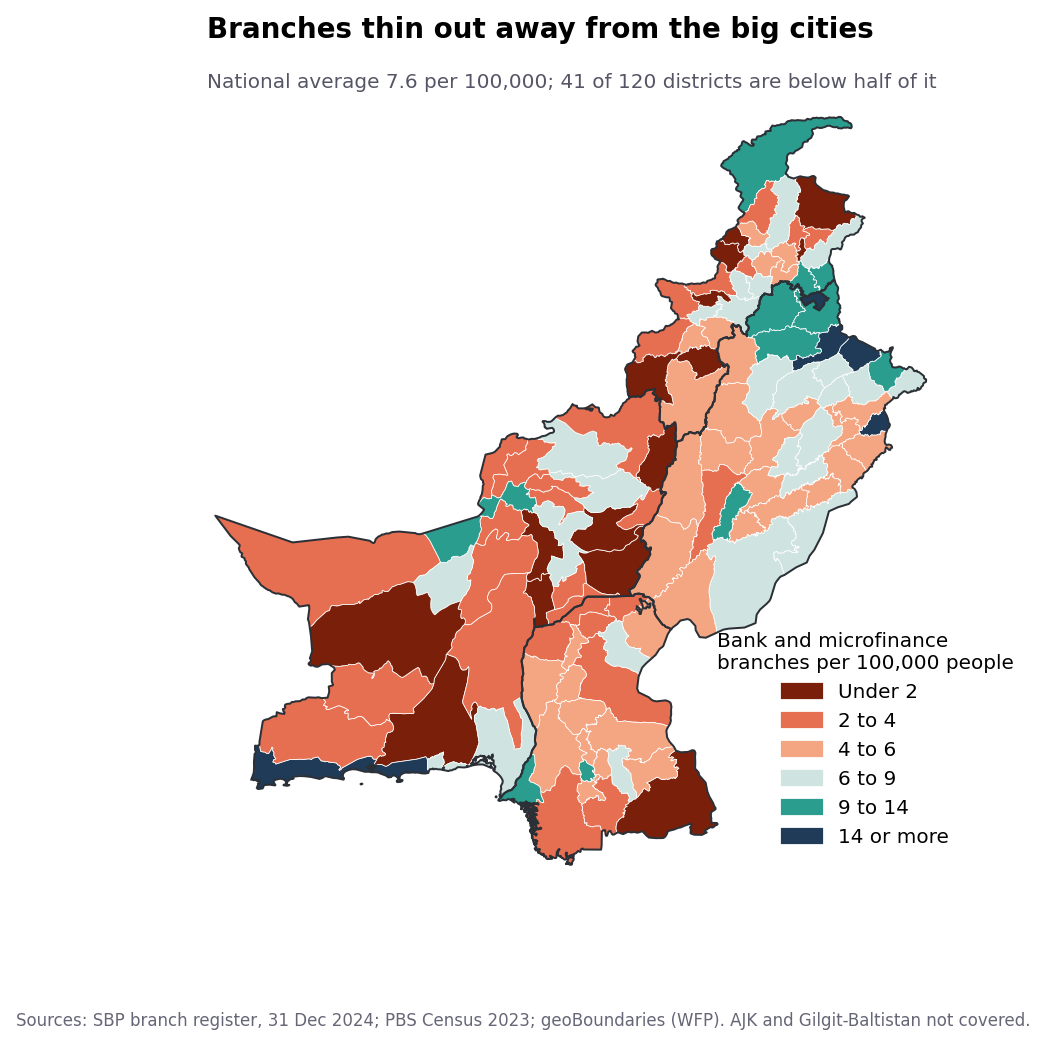

In [9]:
display(Image(filename=str(FIGURES / "06_map_branch_density.png"), width=620))

## 6. How many branches should a district have?

A negative binomial model of branch counts on population, urban share and a development index. Each district's expected
count comes from a fit that leaves that district out, so a district never helps to predict itself. The notebook refits the
model from scratch and checks it against the pipeline.

In [10]:
df = models.prepare(units.drop(columns=[c for c in units.columns if c in ("log_pop", "urban", "log_density", "log_branch_density")]))
y = df["branches_2024"].to_numpy(float)
Xm = sm.add_constant(df[models.MODEL_FEATURES]).to_numpy()
full = models._fit_nb(y, Xm)
names = ["intercept", *models.MODEL_FEATURES, "alpha"]
pd.DataFrame({"coef": full.params, "std err": full.bse, "p": full.pvalues}, index=names).round(3)

,coef,std err,p
intercept,-7.396,0.605,0.0
log_pop,0.803,0.043,0.0
urban,1.008,0.194,0.0
ses_index,0.528,0.041,0.0
alpha,0.072,0.013,0.0


In [11]:
expected, failures = models._loo_predictions(y, Xm, full)
assert failures == 0
assert np.allclose(expected, units["expected_branches"], rtol=1e-6)
print("Leave-one-out expectations match the pipeline to 6 digits")

p_below, _ = models._nb_cdf(y, expected, float(full.params[-1]))
gap = pd.DataFrame({"unit": units["unit"], "branches": y, "expected": expected.round(0), "shortfall": (expected - y).round(0),
                    "chance_of_so_few": p_below.round(3)})
gap.sort_values("shortfall", ascending=False).head(8)

Leave-one-out expectations match the pipeline to 6 digits


,unit,branches,expected,shortfall,chance_of_so_few
58,Lahore,1960.0,2416.0,456.0,0.255
23,Gujranwala,482.0,782.0,300.0,0.060
41,Karachi,2705.0,2963.0,258.0,0.404
100,Sheikhupura,241.0,384.0,143.0,0.070
30,Hyderabad,261.0,400.0,139.0,0.087
21,Faisalabad,696.0,827.0,131.0,0.300
44,Kasur,176.0,292.0,116.0,0.056
26,Hafizabad,91.0,146.0,55.0,0.074


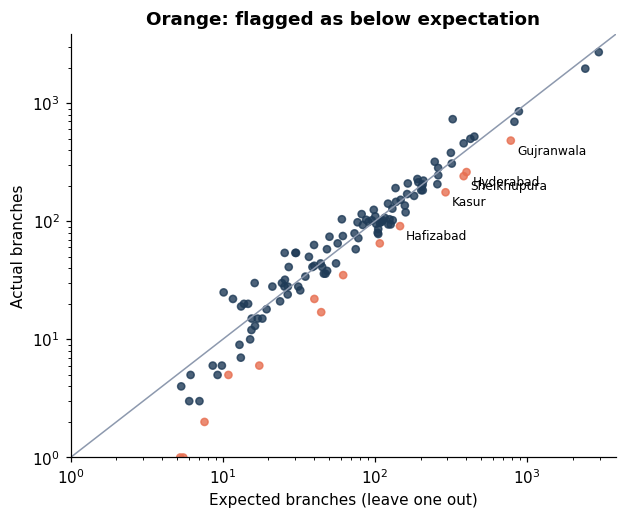

Total shortfall 2,362 branches; 15 districts flagged for review


In [12]:
fig, ax = plt.subplots(figsize=(6.4, 5))
colour = np.where(units["robust_shortfall"], config.ORANGE, config.NAVY)
ax.scatter(expected, y, s=22, c=colour, alpha=0.8)
lim = [1, max(expected.max(), y.max()) * 1.3]
ax.plot(lim, lim, color=config.GREY, lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
for _, row in units[units["robust_shortfall"]].nlargest(5, "branch_gap").iterrows():
    ax.annotate(row["unit"], (row["expected_branches"], row["branches_2024"]), fontsize=8, xytext=(4, -9), textcoords="offset points")
ax.set_xlabel("Expected branches (leave one out)"); ax.set_ylabel("Actual branches")
ax.set_title("Orange: flagged as below expectation")
plt.show()
print(f"Total shortfall {np.maximum(expected - y, 0).sum():,.0f} branches; {int(units['robust_shortfall'].sum())} districts flagged for review")

## 7. Types of district

K-means on four standardised variables gives four types. They form a continuum rather than sharp groups (silhouette about 0.3), so
the types are a summary, not a discovery.

In [13]:
clustered, info = models.cluster_units(units.drop(columns=["cluster", "cluster_rank"]))
assert (clustered["cluster"].to_numpy() == units["cluster"].to_numpy()).all()
pd.DataFrame(info["profile"]).round(1)

,cluster,units,population,urban_share,ses_index,literacy_female,branches_per_100k,mfb_share,rural_branch_share,cluster_rank,largest_units
0,Frontier and remote,28,15947883.0,9.7,-1.2,21.5,1.7,2.1,76.1,0,"Tharparkar, Bajaur, Khyber, Kohistan"
1,Developing rural,37,41658386.0,24.4,-0.5,32.6,4.3,10.3,58.7,1,"Khairpur, Rajanpur, Sanghar, Dera Ismail Khan"
2,Established districts,45,113378091.0,25.3,0.8,52.0,6.0,11.0,47.9,2,"Rahim Yar Khan, Muzaffargarh, Peshawar, Sialkot"
3,Metropolitan hubs,10,70515071.0,64.8,1.6,69.6,12.0,4.6,15.9,3,"Karachi, Lahore, Faisalabad, Rawalpindi"


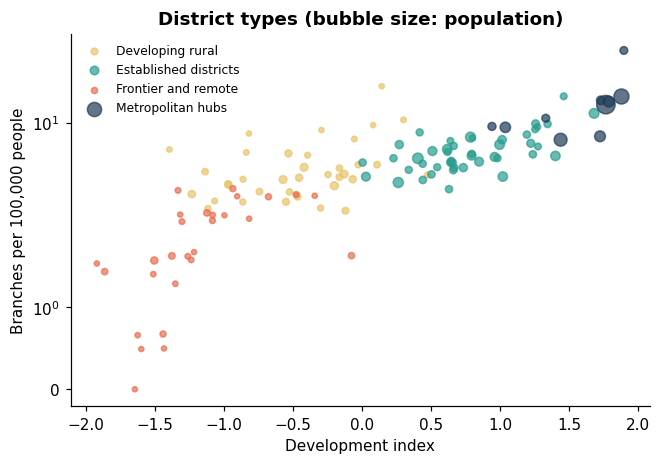

In [14]:
fig, ax = plt.subplots(figsize=(6.8, 4.4))
palette = dict(zip(models.CLUSTER_NAMES, [config.ORANGE, config.AMBER, config.TEAL, config.NAVY]))
for name, g in units.groupby("cluster"):
    ax.scatter(g["ses_index"], g["branches_per_100k"], s=g["pop"] / 1.5e5 + 10, alpha=0.7, label=name, color=palette[name])
ax.set_yscale("symlog", linthresh=2)
ax.set_xlabel("Development index"); ax.set_ylabel("Branches per 100,000 people")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("District types (bubble size: population)")
plt.show()

## 8. Inequality and catch-up

The Gini coefficient measures how unevenly branches are spread against population, and a regression asks whether districts that
started with fewer bank branches per person gained more between 2020 and 2024.

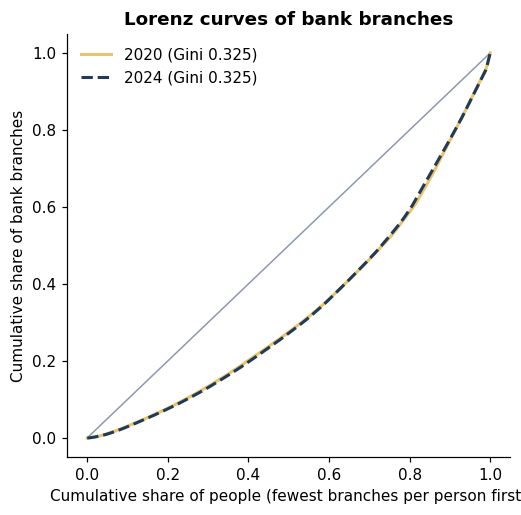

In [15]:
x20, y20, g20 = models.lorenz(units["pop_2017"].to_numpy(float), units["banks_2020"].to_numpy(float))
x24, y24, g24 = models.lorenz(units["pop"].to_numpy(float), units["banks_2024"].to_numpy(float))
assert abs(g24 - r.summary["inequality"]["banks_2024"]["gini"]) < 1e-9
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=config.GREY, lw=1)
ax.plot(x20, y20, color=config.AMBER, lw=2, label=f"2020 (Gini {g20:.3f})")
ax.plot(x24, y24, color=config.NAVY, lw=2, ls="--", label=f"2024 (Gini {g24:.3f})")
ax.set_xlabel("Cumulative share of people (fewest branches per person first)")
ax.set_ylabel("Cumulative share of bank branches")
ax.legend(frameon=False); ax.set_title("Lorenz curves of bank branches")
plt.show()

In [16]:
cx = sm.add_constant(units[["density_2020", "pop_growth_pct_pa"]])
conv = sm.OLS(units["density_change"], cx).fit(cov_type="HC3")
print(conv.summary().tables[1])
low_half = units["density_2020"] < units["density_2020"].median()
print(f"\nDistricts that started in the lower half hold {units.loc[low_half, 'pop'].sum() / units['pop'].sum():.0%} of people and "
      f"received {units.loc[low_half, 'banks_change'].sum() / units['banks_change'].sum():.0%} of {units['banks_change'].sum():,} net new bank branches")

                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.0048      0.474      0.010      0.992      -0.924       0.933
density_2020          0.0205      0.047      0.436      0.663      -0.072       0.113
pop_growth_pct_pa     0.0146      0.152      0.096      0.923      -0.284       0.313

Districts that started in the lower half hold 30% of people and received 15% of 2,766 net new bank branches


## 9. A placement planner

If 1,000 new access points are added, where should they go? Three rules place them one at a time; each is judged on the same
five outcomes. The result that matters: **where points go decides who is reached**, and the rules disagree.

In [17]:
k = r.scenario["default_k"]
rows = {"Today": models.outcomes(units)}
for name in models.STRATEGIES:
    rows[name] = models.outcomes(units, models.allocate(units, k, name))
planner = pd.DataFrame({k_: v.as_dict() for k_, v in rows.items()}).T.apply(pd.to_numeric)
planner["population_below_half"] = (planner["population_below_half"] * 100).round(1)
planner["gini"] = planner["gini"].round(3)
planner["share_to_low_female_literacy"] = (planner["share_to_low_female_literacy"] * 100).round(0)
saved = {s["strategy"]: s for s in r.summary["scenario_default"]}
assert planner.loc["equity", "units_below_half"] == saved["equity"]["units_below_half"]
assert abs(rows["equity"].gini - saved["equity"]["gini"]) < 1e-9
planner[["units_below_half", "population_below_half", "gini", "worst_people_per_branch", "placed", "share_to_low_female_literacy"]]

,units_below_half,population_below_half,gini,worst_people_per_branch,placed,share_to_low_female_literacy
Today,41.0,13.6,0.304,203368.00,0.0,NaN
equity,0.0,0.0,0.246,22369.75,1000.0,90.0
gap,44.0,16.9,0.321,203368.00,1000.0,0.0
women,20.0,7.2,0.260,65055.00,1000.0,86.0


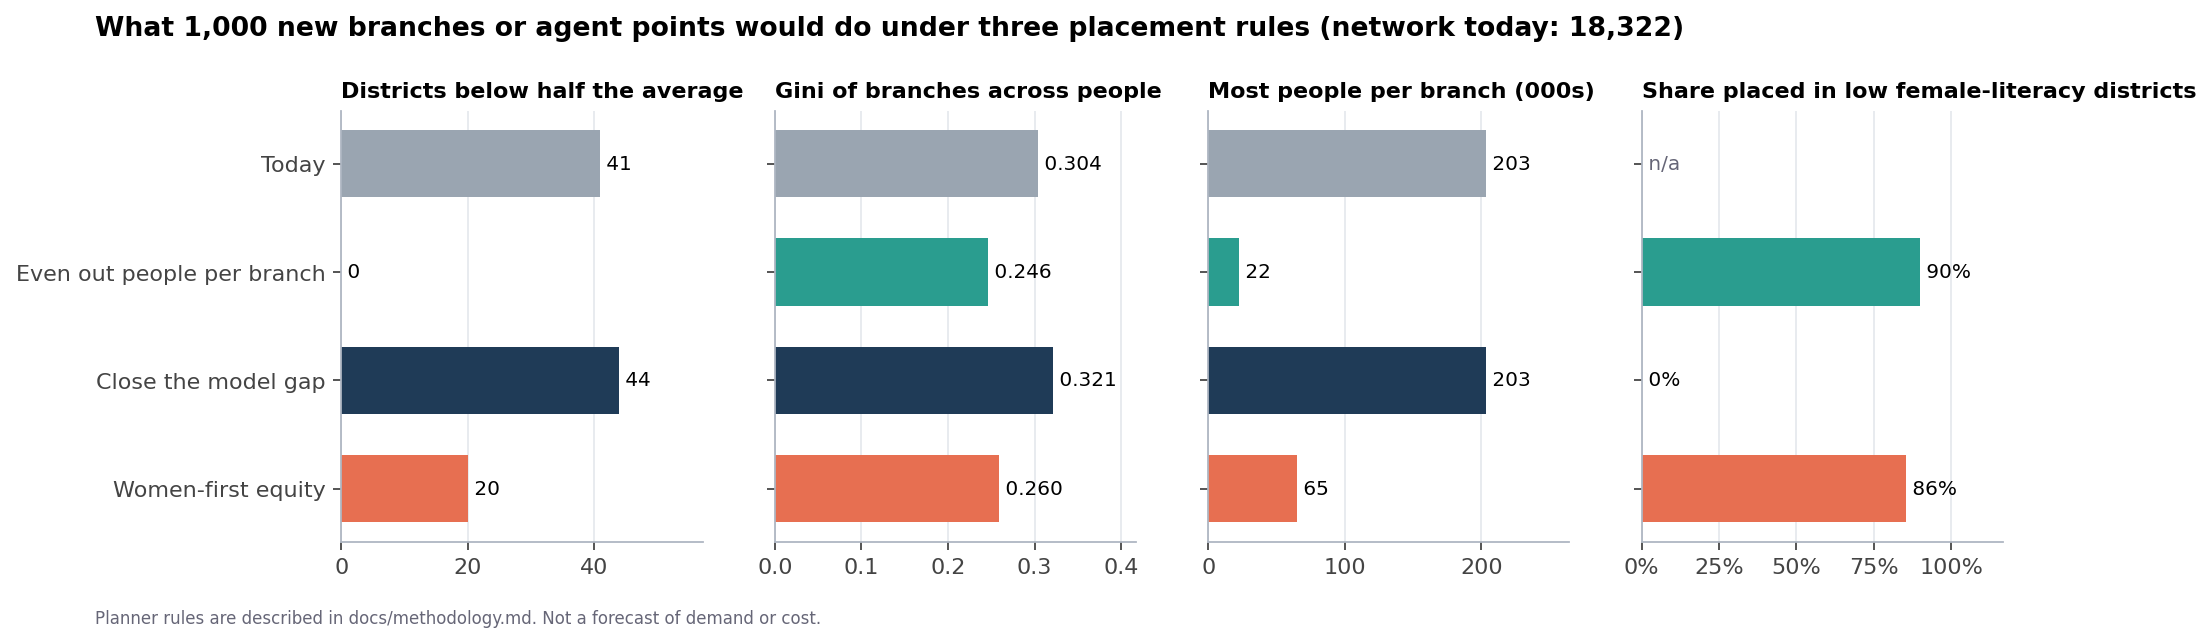

In [18]:
display(Image(filename=str(FIGURES / "14_planner_outcomes.png"), width=720))

## 10. The digital layer

Wallet accounts and agents from the State Bank's quarterly statistics. Agents have grown, but a falling share is active.

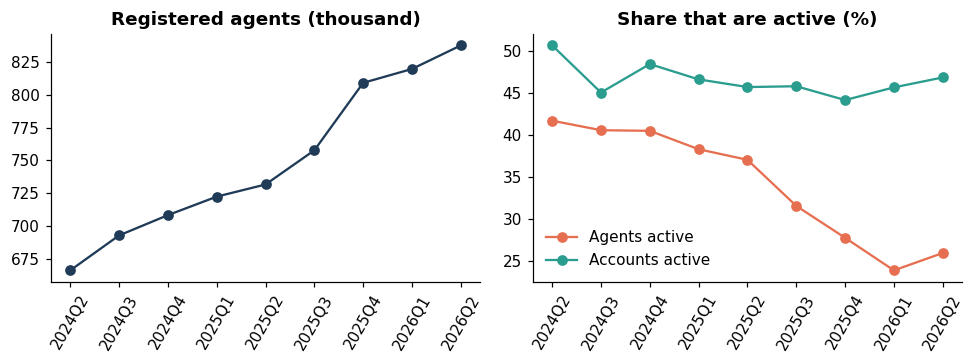

In [19]:
nat = r.bb_national.copy()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(nat["quarter"], nat["agents"] / 1e3, marker="o", color=config.NAVY)
axes[0].set_title("Registered agents (thousand)")
axes[1].plot(nat["quarter"], nat["active_agent_share"], marker="o", color=config.ORANGE, label="Agents active")
axes[1].plot(nat["quarter"], nat["active_account_share"], marker="o", color=config.TEAL, label="Accounts active")
axes[1].set_title("Share that are active (%)"); axes[1].legend(frameon=False)
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 11. Conclusions

Every figure below is computed above, not typed.

In [20]:
pak_row = r.summary["cross_country"]["pakistan"]
conv_p = conv.pvalues["density_2020"]
print(f"- Only {pak_row['account']:.0f}% of adults have an account: {pak_row['shortfall_pts']:.0f} points below the {pak_row['expected']:.0f}% that income predicts.")
print(f"- Women {pak_row['account_women']:.0f}% against men {pak_row['account_men']:.0f}%; phones {pak_row['phone_women']:.0f}% against {pak_row['phone_men']:.0f}%.")
print(f"- Rural Pakistan has {total.rural_branches_2024 / total.pop_rural * 1e5:.1f} branches per 100,000 against {total.urban_branches_2024 / total.pop_urban * 1e5:.1f} urban.")
print(f"- Districts that started behind did not catch up (slope {conv.params['density_2020']:.3f}, p = {conv_p:.2f}).")
print(f"- {k:,} new points placed to even out people per branch cut the Gini from {rows['Today'].gini:.3f} to {rows['equity'].gini:.3f}; "
      f"placed by the model gap they raise it to {rows['gap'].gini:.3f}.")

- Only 27% of adults have an account: 25 points below the 53% that income predicts.
- Women 12% against men 42%; phones 30% against 95%.
- Rural Pakistan has 3.7 branches per 100,000 against 13.7 urban.
- Districts that started behind did not catch up (slope 0.020, p = 0.66).
- 1,000 new points placed to even out people per branch cut the Gini from 0.304 to 0.246; placed by the model gap they raise it to 0.321.
